This notebook shows the discrimination power of the likelihood metric against the current chi2 at particle identification

# Run on Gen 2 Analysis Full Run 1 MC + Fixed Dev Sample

Run this every time to load all necessary (?) libraries

In [4]:
import glob, os, time
from multiprocessing import Pool
import warnings
import numpy as np
import pandas as pd
import gc
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import matplotlib.ticker as mticker
from analysis_village.plot_style import sbnd_style   # applies SBND rcParams on import

import sys
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
for m in [m for m in sys.modules if m == "makedf" or m.startswith("makedf.")]:
    del sys.modules[m]
from makedf import llpid


DFS = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/"         # grid outputs
SKIM = "/exp/sbnd/data/users/maxd/outputDF/llpid_skim/"          # skimmed files


Whenever using a new cafpyana sample, we want to load in and read all the necessary data; we skim through these files and chunk them to conserve compute. 

The next 4 cells only need to be run once per new samples.

In [ ]:
PART_SIZE = 1000   # grid output files per skim file

# grid output directories per sample (original run + reruns of the missing jobs)
SAMPLES = {
    "mc":      ["2026_10_29_071429__Full_MC_LLPID_run1gen2",         "2026_10_29_165936__Full_MC_LLPID_run1gen2_1029redo"],
    "offbeam": ["2026_10_28_163745__Full_Offbeam_LLPID_run1gen2"],
    "data":    ["2026_10_30_091254__Full_Data_LLPID_run1gen2_fixed"],
}

# columns to keep: every column whose name starts with one of these
KEEP = [
    ("slc", "is_clear_cosmic"), ("slc", "nu_score"), ("slc", "vertex"), ("slc", "opt0", "score"),
    ("slc", "barycenterFM"),
    ("slc", "tmatch"), ("slc", "truth", "pdg"), ("slc", "truth", "iscc"), ("slc", "truth", "E"),
    ("pfp", "trackScore"), ("pfp", "dist_to_vertex"), ("pfp", "parent_is_primary"),
    ("pfp", "trk", "len"), ("pfp", "trk", "start"), ("pfp", "trk", "end"), ("pfp", "trk", "dir"),
    ("pfp", "trk", "chi2pid"), ("pfp", "trk", "rangeP"), ("pfp", "trk", "mcsP"),
    ("pfp", "trk", "llpid"),
    ("pfp", "trk", "truth", "p", "pdg"), ("pfp", "trk", "truth", "p", "cont_tpc"),
    ("pfp", "trk", "truth", "p", "startE"), ("pfp", "trk", "truth", "p", "end_process"),
    ("pfp", "trk", "truth", "p", "length"), ("pfp", "trk", "truth", "p", "interaction_id"),
]

def skim(f):
    hdr = pd.read_hdf(f, "hdr_0")
    pot = pd.read_hdf(f, "pot_0")
    histpot = pd.read_hdf(f, "histpotdf_0")
    evt = pd.read_hdf(f, "evt_0")

    # drop slices pandora flags as clear cosmics
    evt = evt[evt["slc", "is_clear_cosmic"] == 0]

    cols = [c for c in evt.columns if any(c[:len(k)] == k for k in KEEP) and c[3] != "version"]
    evt = evt[cols]
    floats = evt.columns[evt.dtypes == np.float64]
    evt[floats] = evt[floats].astype(np.float32)

    norm = {"file": f,
            "mc_pot": histpot["TotalPOT"].sum(),
            "bnb_pot": pot["TOR875"].sum(),
            "bnb_gates": len(pot),
            "offbeam_gates": hdr["noffbeambnb"].sum(),
            "n_events": len(hdr)}
    return evt, norm

def make_skim(sample, parts=None):
    """parts: None = all chunks, an int = that chunk only, or a list of chunk numbers"""
    files = sorted(f for d in SAMPLES[sample] for f in glob.glob(DFS + d + "/*.df"))
    os.makedirs(SKIM, exist_ok=True)
    starts = list(range(0, len(files), PART_SIZE))
    if parts is None:
        parts = range(len(starts))
    elif isinstance(parts, int):
        parts = [parts]
    print(f"{sample}: {len(files)} files, {len(starts)} chunks, skimming {list(parts)}", flush=True)

    for part in parts:
        start = starts[part]
        t = time.time()
        with Pool(4) as p:
            out = p.map(skim, files[start:start + PART_SIZE], chunksize=10)

        norm = pd.DataFrame([o[1] for o in out])
        # the 'file' index level makes (file, __ntuple, entry, slc, pfp) unique across files
        evt = pd.concat([o[0] for o in out], keys=range(start, start + len(out)), names=["file"])
        n_files = len(out)
        del out
        gc.collect()

        outfile = SKIM + f"llpid_skim_{sample}_{part:02d}.h5"
        evt.to_hdf(outfile, key="evt", mode="w")
        norm.to_hdf(outfile, key="norm")
        print(f"wrote {outfile}: {n_files} files, {len(evt)} rows, {time.time() - t:.0f} s", flush=True)
        del evt, norm
        gc.collect()


The next 3 lines will skim the entirety of the processed files skimming pertinent information; Only needs to be run once per set of cuts.

In [3]:
make_skim("data")


data: 1817 files, 2 chunks, skimming [0, 1]


wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_00.h5: 1000 files, 192049 rows, 118 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_01.h5: 817 files, 155724 rows, 89 s


In [ ]:
make_skim("offbeam")
# make_skim("offbeam", [0,1])


offbeam: 9993 files, 10 chunks, skimming [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_00.h5: 1000 files, 732644 rows, 123 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_01.h5: 1000 files, 697330 rows, 130 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_02.h5: 1000 files, 717518 rows, 139 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_03.h5: 1000 files, 689750 rows, 272 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_04.h5: 1000 files, 715653 rows, 525 s


In [ ]:
make_skim("mc")
# make_skim("mc", [0, 1])

mc: 10000 files, 10 chunks, skimming [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_00.h5: 1000 files, 3347254 rows, 159 s


: 

Once ran, can load files from here

In [6]:

def in_volume(x, y, z):
    """SBND Gen 1 contained volume: 5 < |x| < 190 (±5 cm cathode cut);
    10 < z < 250, |y| < 190; 250 < z < 450: -190 < y < 100 in East TPC (x < 0), |y| < 190 in West TPC (x > 0)"""
    x_region  = (np.abs(x) > 5) & (np.abs(x) < 190)
    z_region1 = (z > 10) & (z < 250) & (y > -190) & (y < 190)
    z_region2 = (z > 250) & (z < 450) & (y > -190) & (y < 100) & (x < 0)
    z_region3 = (z > 250) & (z < 450) & (y > -190) & (y < 190) & (x > 0)
    return x_region & (z_region1 | z_region2 | z_region3)


def in_fv(df):
    return in_volume(df["slc", "vertex", "x"], df["slc", "vertex", "y"], df["slc", "vertex", "z"])

def trk_contained(df):
    """track start and end inside the Gen 1 volume and in the same TPC (no cathode crossing)"""
    s = [df["pfp", "trk", "start", c] for c in "xyz"]
    e = [df["pfp", "trk", "end", c] for c in "xyz"]
    return in_volume(*s) & in_volume(*e) & (np.sign(s[0]) == np.sign(e[0]))

def valid_chi(df):
    return (df["pfp", "trk", "chi2pid", "I2", "chi2_proton"] != 0) & (df["pfp", "trk", "chi2pid", "I2", "chi2_muon"] != 0) & (df["pfp", "trk", "chi2pid", "I2", "chi2_pion"] != 0)

# Event selection mask
def selection(df):
    return (in_fv(df)
            & trk_contained(df)
            & (df["slc", "is_clear_cosmic"] == 0)
            & (df["pfp", "trk", "len"] > 3)
            & (df["pfp", "trackScore"] > 0.5)
            & (df["pfp", "dist_to_vertex"] < 6)
            & (df["slc", "barycenterFM", "flashPEs"] > 3000)
            & valid_chi(df)
            & LL(df, "ell_mu").notna())



CATS = ["muon", "proton", "pion", "other"]
COLORS = ["tab:red", "tab:blue", "tab:green", "tab:gray", "tab:purple"]

LL  = lambda df, name: df["pfp", "trk", "llpid", name]
CHI = lambda df, name: df["pfp", "trk", "chi2pid", "I2", name]

#Define all the variables we want to plot
VARS = [
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-4000, 4000, 151), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-1000, 1000, 151), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-400, 400, 151), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-100, 100, 151), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_pi"),       np.linspace(-4000, 4000, 151), r"$\ell_p - \ell_\pi$"),
    (lambda d: LL(d, "ell_pi") - LL(d, "ell_mu"),      np.linspace(-1000, 800, 181),   r"$\ell_\pi - \ell_\mu$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-4500, 6500, 111),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-1000, 1000, 111),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-500, 500, 111),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-100, 100, 111),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_pi"),     np.linspace(-4500, 6500, 111),  r"$\ell_{0p} - \ell_{0\pi}$"),
    (lambda d: LL(d, "ell0_pi") - LL(d, "ell0_mu"),    np.linspace(-1000, 600, 161),   r"$\ell_{0\pi} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell_mu"),                        np.linspace(-100, 6000, 123),   r"$\ell_\mu$"),
    (lambda d: LL(d, "ell_pi"),                        np.linspace(-100, 6000, 123),   r"$\ell_\pi$"),
    (lambda d: LL(d, "ell_p"),                         np.linspace(-100, 13000, 132),  r"$\ell_p$"),
    (lambda d: LL(d, "ell0_mu"),                       np.linspace(-100, 6000, 123),   r"$\ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_pi"),                       np.linspace(-100, 6000, 123),   r"$\ell_{0\pi}$"),
    (lambda d: LL(d, "ell0_p"),                        np.linspace(-100, 9000, 92),    r"$\ell_{0p}$"),
    (lambda d: LL(d, "dl_mu"),                         np.arange(-100.5, 600, 5),      r"$dL_\mu$ [cm]"),
    (lambda d: LL(d, "dl_p"),                          np.arange(-100.5, 600, 5),      r"$dL_p$ [cm]"),
    (lambda d: LL(d, "nhits_mu"),                      np.arange(-0.5, 3250, 50),      "LLPID hits (all planes)"),
    (lambda d: CHI(d, "chi2_proton") - CHI(d, "chi2_muon"), np.linspace(-100, 1000, 221), r"$\chi^2_p - \chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_proton"),                  np.linspace(0, 1000, 201),      r"$\chi^2_p$"),
    (lambda d: CHI(d, "chi2_muon"),                    np.linspace(0, 100, 101),       r"$\chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_pion"),                    np.linspace(0, 120, 121),       r"$\chi^2_\pi$"),
    (lambda d: d["pfp", "trk", "len"],                 np.linspace(0, 600, 61),        "track length [cm]"),
]




Read through variables and fill histograms using the event selection function

In [7]:
import gc

#Defines overflow and underflow bins for histograms
def flow_hist(v, bins):
    """[underflow, np.histogram counts..., overflow]; NaN goes nowhere"""
    return np.r_[np.sum(v < bins[0]), np.histogram(v, bins)[0], np.sum(v > bins[-1])]

def fill(sample, nparts=None):
    """fill every VARS histogram chunk by chunk; MC split by truth category, data/offbeam in 'all'"""
    files = sorted(glob.glob(SKIM + f"llpid_skim_{sample}_*.h5"))[:nparts]
    keys = CATS if sample == "mc" else ["all"]
    H = [{k: np.zeros(len(bins) + 1) for k in keys} for _, bins, _ in VARS]   # [underflow, bins..., overflow]
    norms, n_sel = [], 0

    for f in files:
        evt = pd.read_hdf(f, "evt")
        norms.append(pd.read_hdf(f, "norm"))
        d = evt[selection(evt)]
        del evt

        if sample == "mc":
            pdg = np.abs(d["pfp", "trk", "truth", "p", "pdg"])
            cat = np.select([pdg == 13, pdg == 2212, pdg == 211], ["muon", "proton", "pion"], "other")
        for h, (var, bins, _) in zip(H, VARS):
            vals = np.asarray(var(d), float)
            for k in keys:
                h[k] += flow_hist(vals if k == "all" else vals[cat == k], bins)

        n_sel += len(d)
        print(f"{os.path.basename(f)}: {len(d)} selected", flush=True)
        del d
        gc.collect()

    norm = pd.concat(norms)
    print(f"{sample}: {len(files)} skim files, {len(norm)} grid files, {n_sel} selected tracks")
    return H, norm

H_data, data_norm = fill("data")
H_off, offbeam_norm = fill("offbeam")
H_mc, mc_norm = fill("mc")


llpid_skim_data_00.h5: 19002 selected
llpid_skim_data_01.h5: 15512 selected
data: 2 skim files, 1817 grid files, 34514 selected tracks
llpid_skim_offbeam_00.h5: 30131 selected
llpid_skim_offbeam_01.h5: 29042 selected
llpid_skim_offbeam_02.h5: 29432 selected
llpid_skim_offbeam_03.h5: 28542 selected
llpid_skim_offbeam_04.h5: 29521 selected
llpid_skim_offbeam_05.h5: 29906 selected
llpid_skim_offbeam_06.h5: 29292 selected
llpid_skim_offbeam_07.h5: 30508 selected
llpid_skim_offbeam_08.h5: 29263 selected
llpid_skim_offbeam_09.h5: 24057 selected
offbeam: 10 skim files, 9993 grid files, 289694 selected tracks
llpid_skim_mc_00.h5: 408369 selected
llpid_skim_mc_01.h5: 406936 selected
llpid_skim_mc_02.h5: 407883 selected
llpid_skim_mc_03.h5: 410056 selected
llpid_skim_mc_04.h5: 409046 selected
llpid_skim_mc_05.h5: 409415 selected
llpid_skim_mc_06.h5: 407016 selected
llpid_skim_mc_07.h5: 408433 selected
llpid_skim_mc_08.h5: 405959 selected
llpid_skim_mc_09.h5: 406843 selected
mc: 10 skim files, 10

In [8]:
#POT Normalization

bnbGates = data_norm["bnb_gates"].sum()
n_events_bnb = data_norm["n_events"].sum()
offbeamGates = offbeam_norm["offbeam_gates"].sum()
n_events_offbeam = offbeam_norm["n_events"].sum()
print("BNB Gates:", bnbGates, " n_events_bnb:", n_events_bnb, " OffBeam Gates:", offbeamGates, " n_events_offbeam:", n_events_offbeam)

p_trig_data = n_events_bnb / bnbGates
p_trig_offbeam = n_events_offbeam / offbeamGates
f_factor = (p_trig_data - p_trig_offbeam) / (1 - p_trig_offbeam)
print("Fudge factor:", f_factor)

offbeam_scale = (1 - f_factor) * bnbGates / offbeamGates
print("Offbeam scale:", offbeam_scale)

pot = data_norm["bnb_pot"].sum()
print("Data POT:", pot)

mc_pot = mc_norm["mc_pot"].sum()
mc_scale = pot / mc_pot 
print("MC POT:", mc_pot, " MC Scale Factor:", mc_scale)


BNB Gates: 960047  n_events_bnb: 89946  OffBeam Gates: 113619953.0  n_events_offbeam: 2225978
Fudge factor: 0.07557841716283481
Offbeam scale: 0.007811023890654768
Data POT: 4.621253e+18
MC POT: 5.401150350598941e+20  MC Scale Factor: 0.008556053005612425


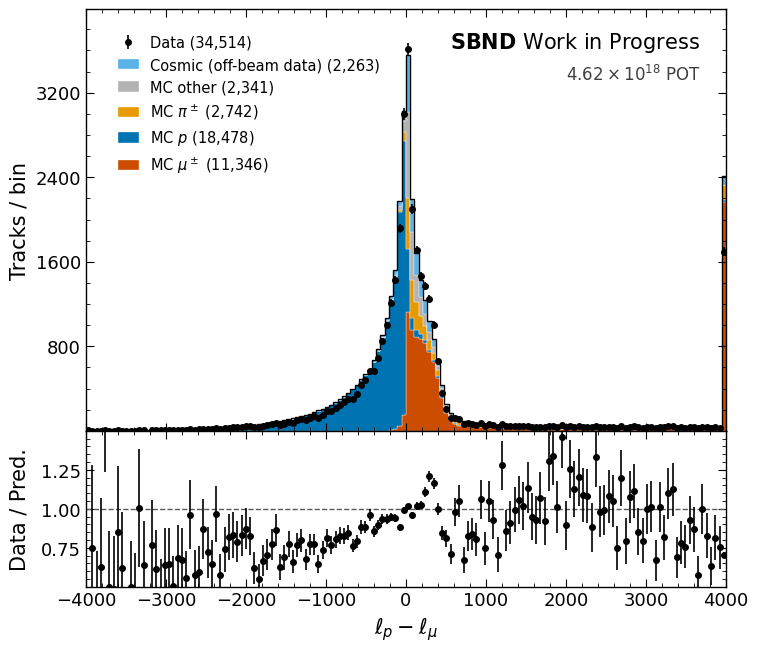

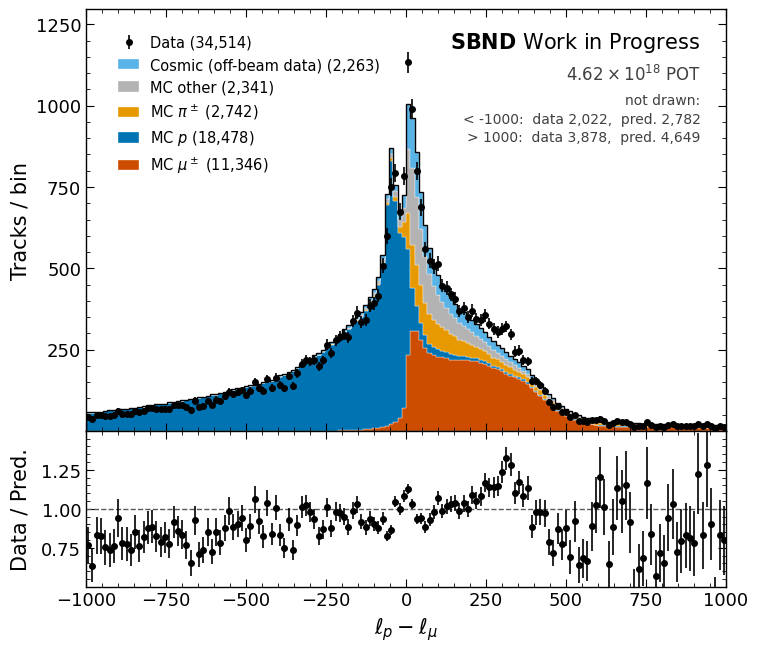

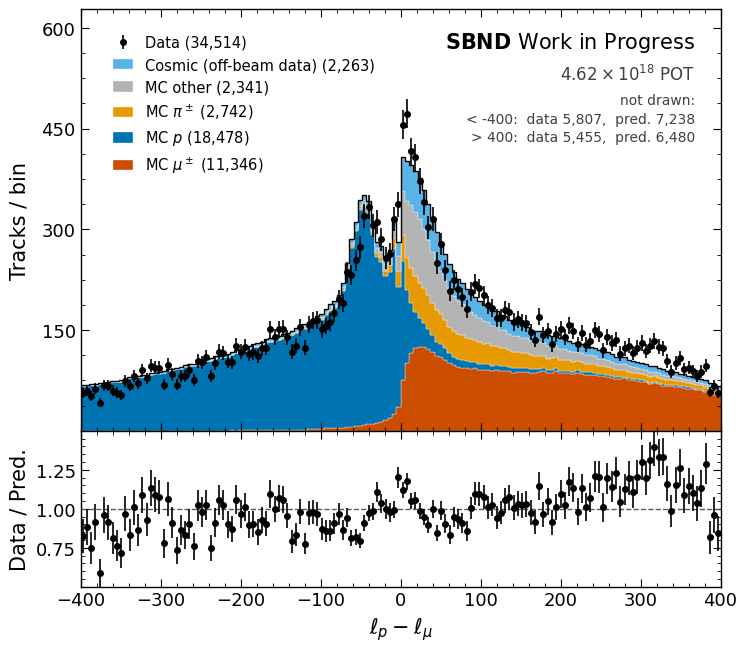

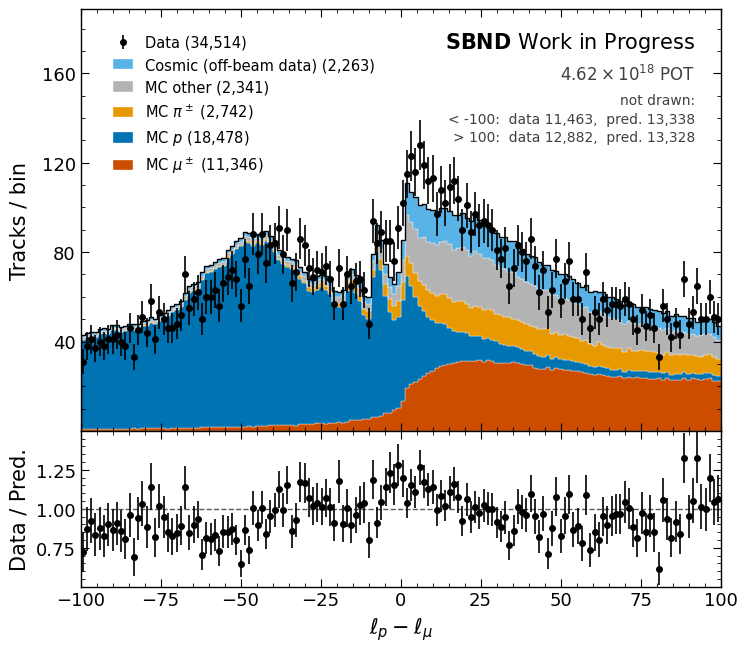

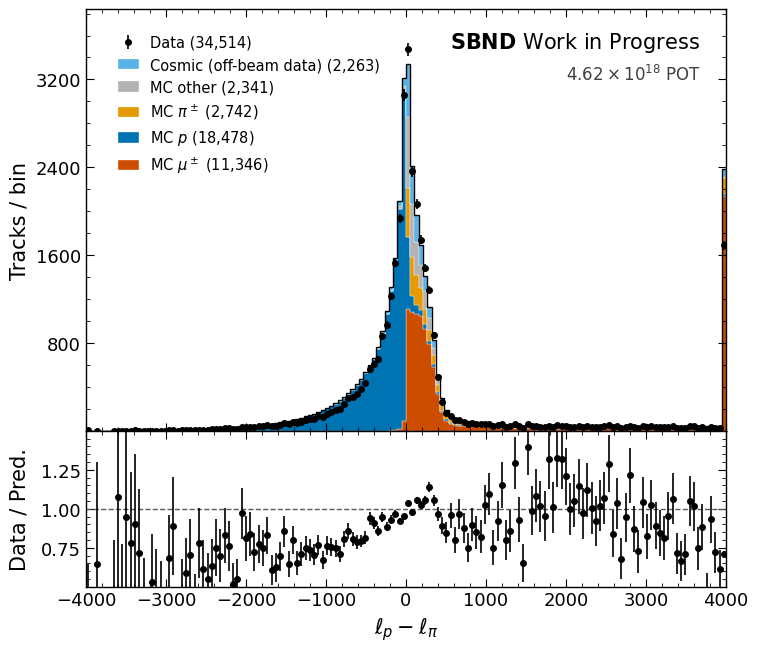

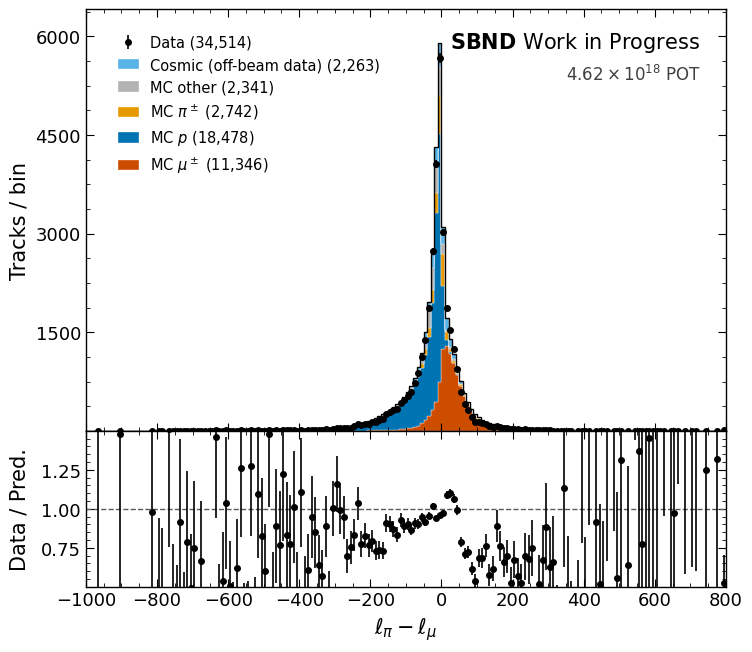

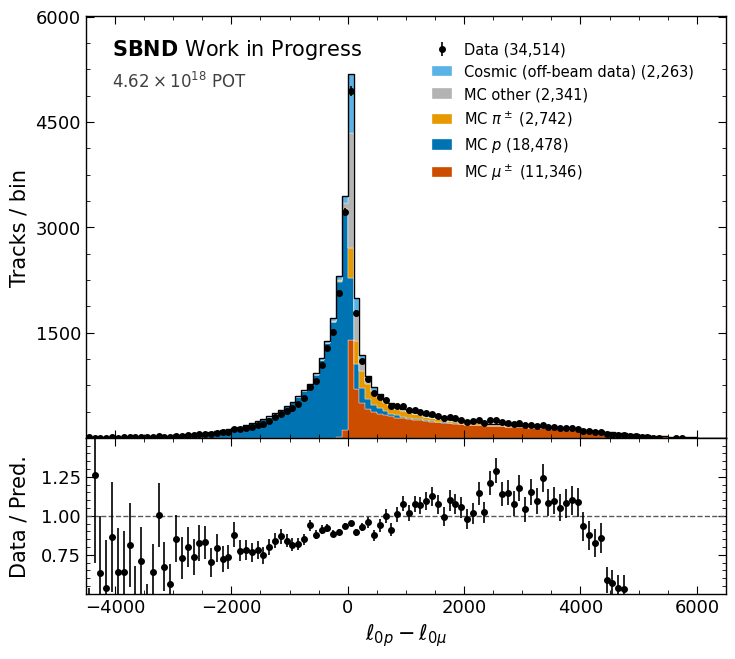

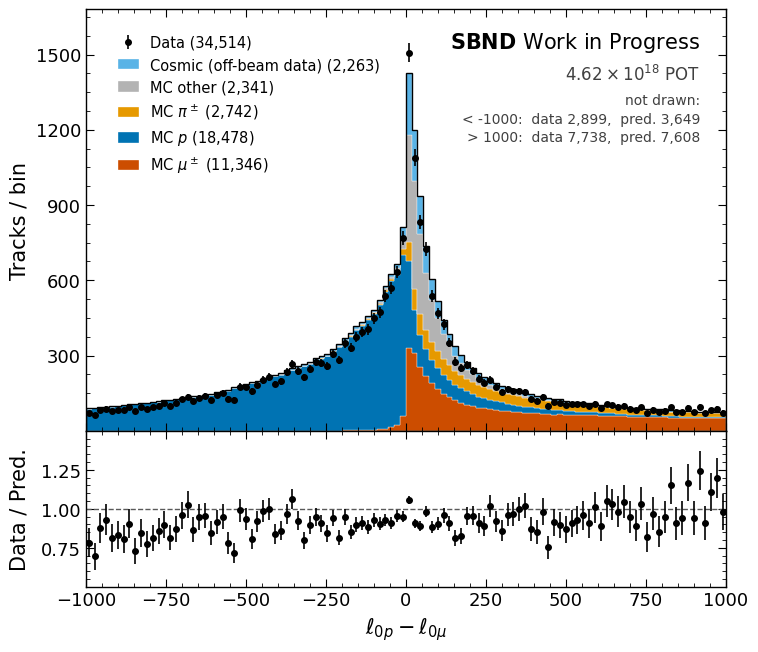

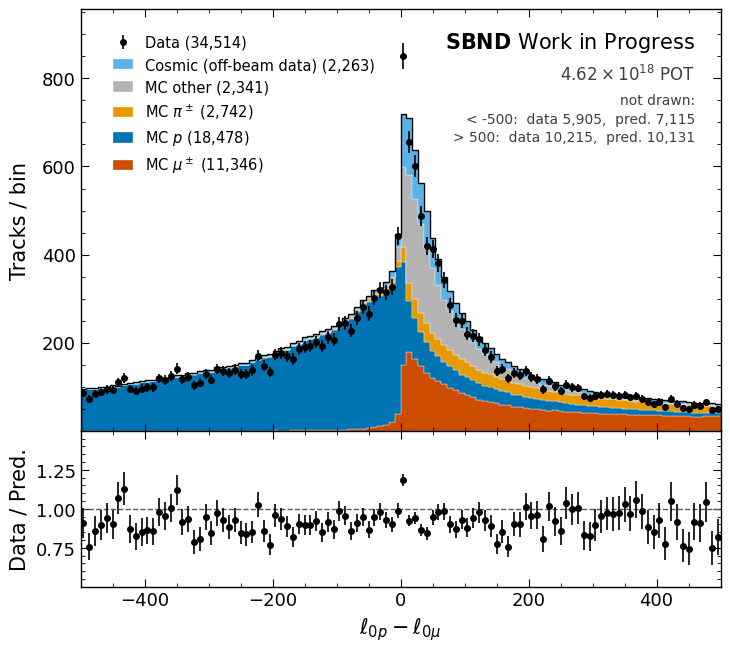

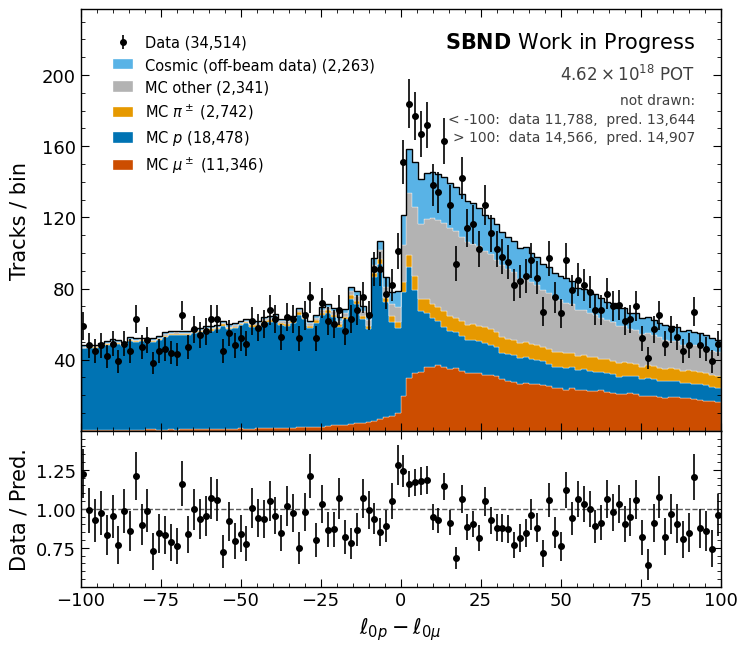

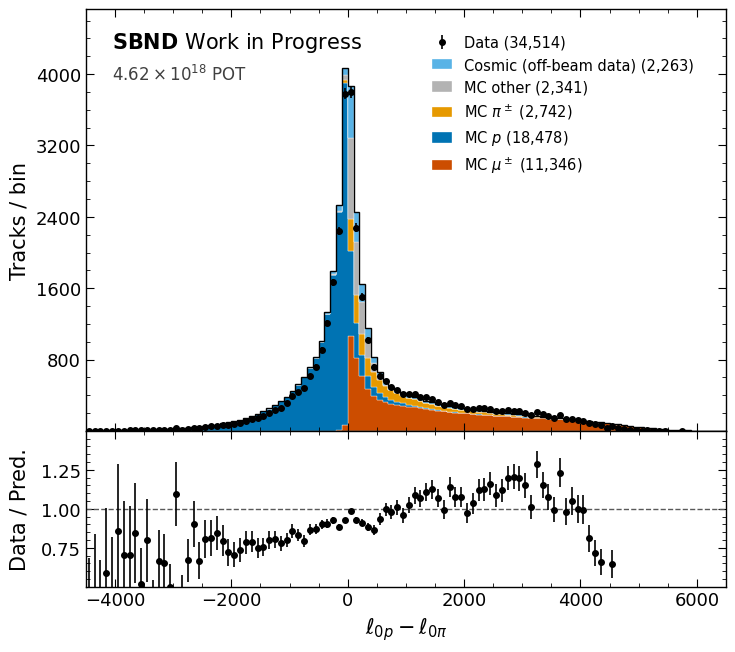

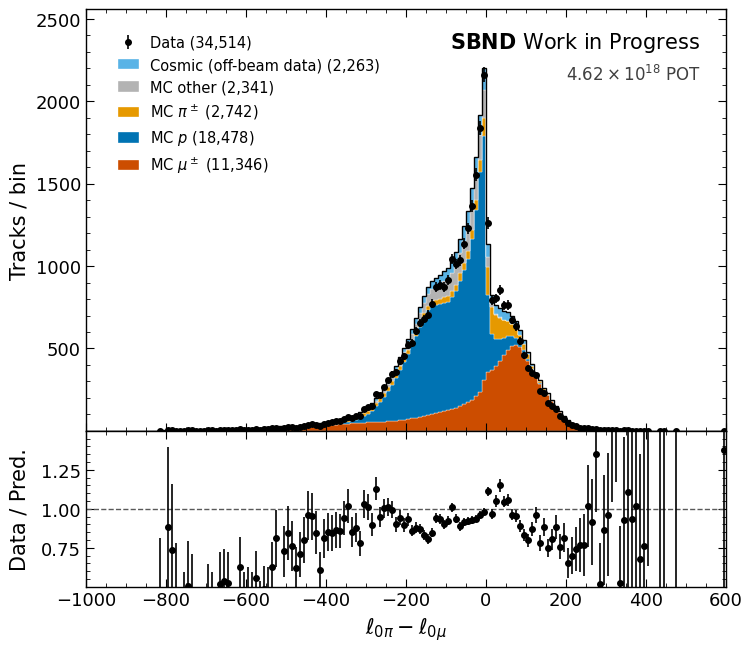

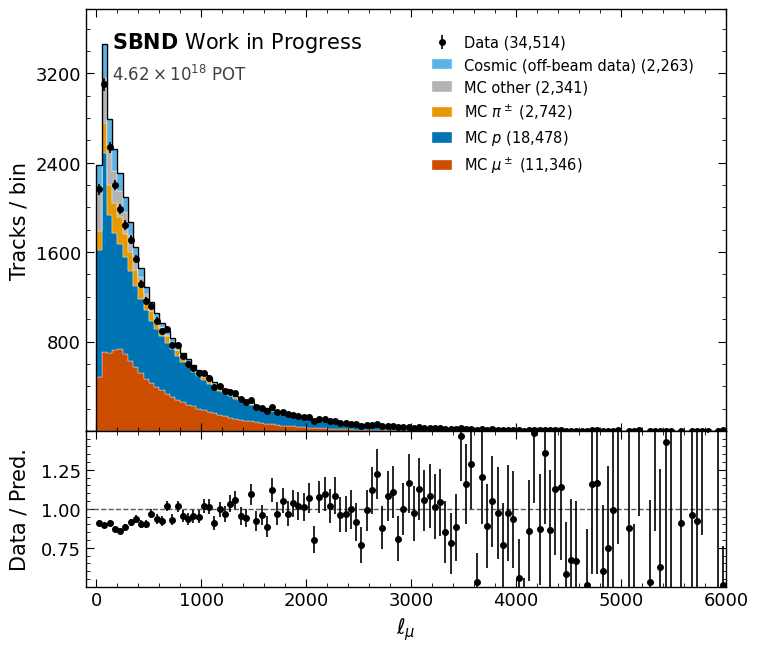

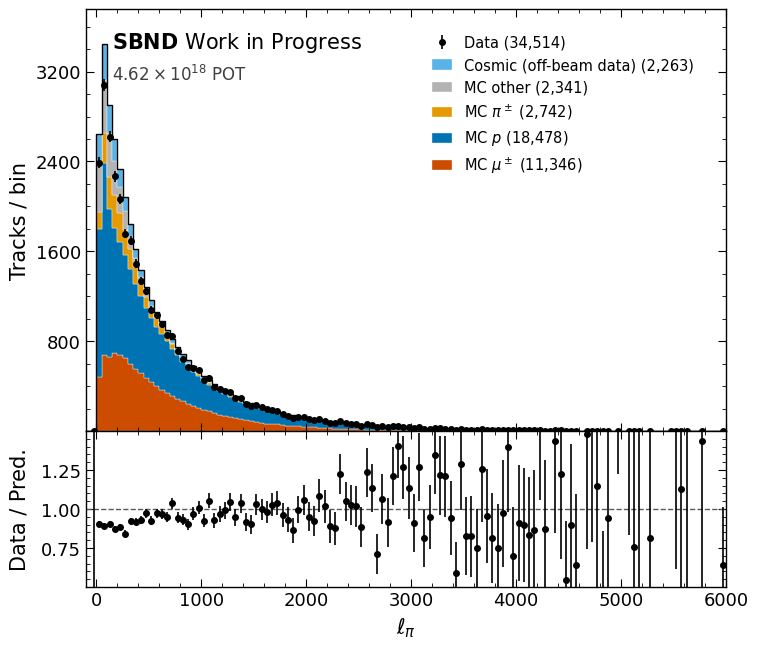

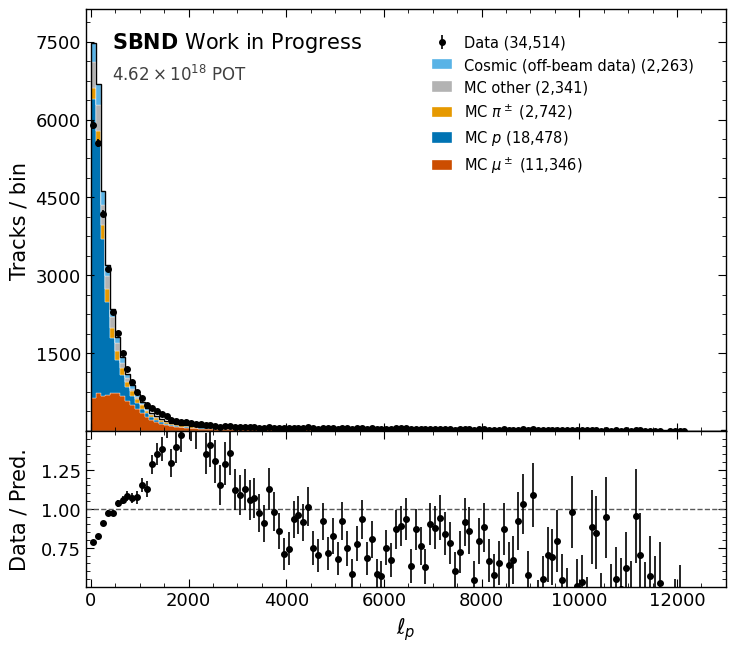

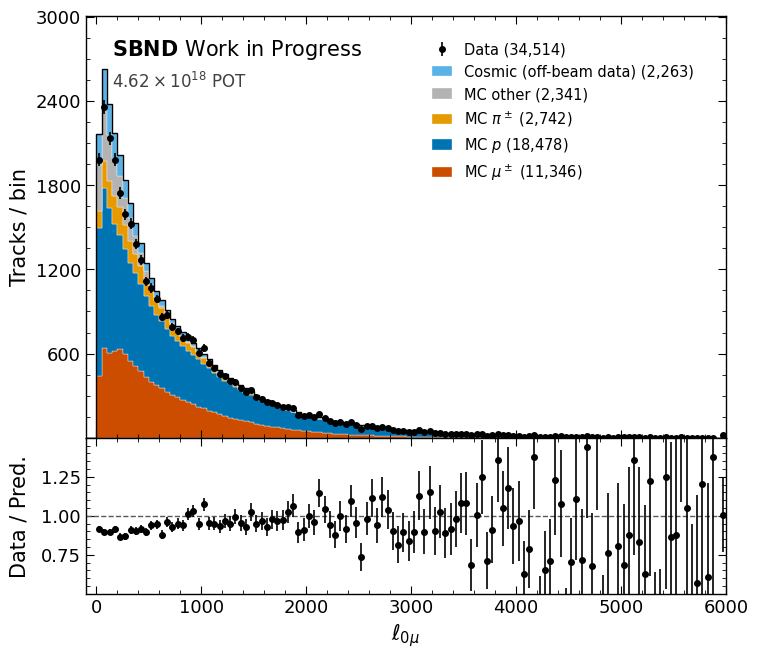

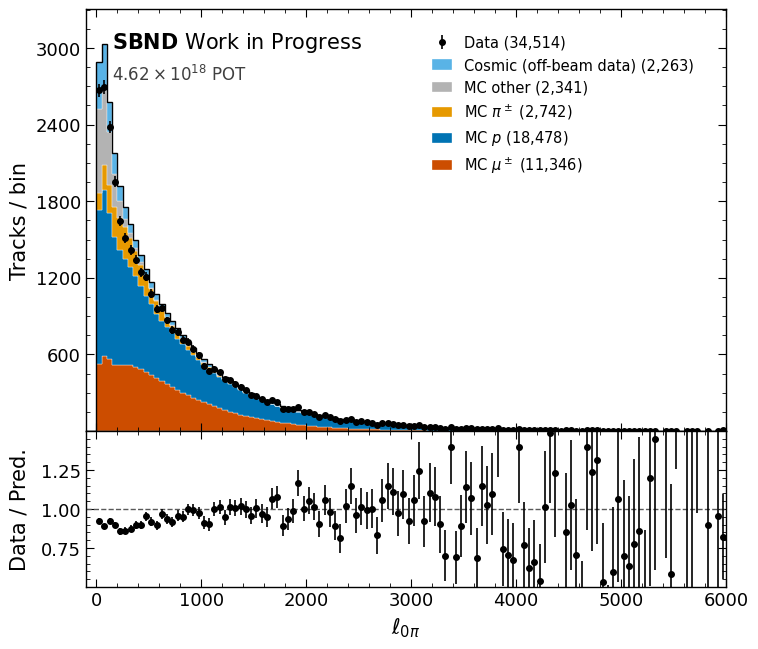

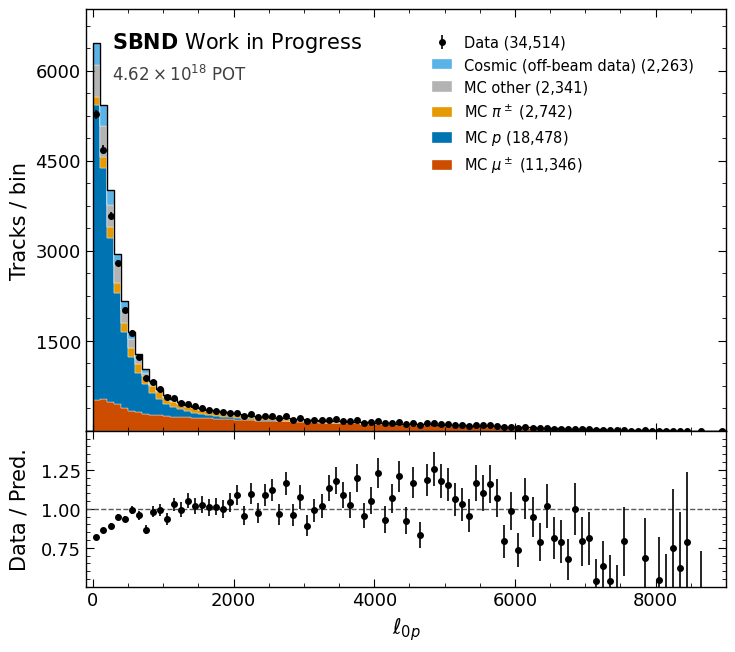

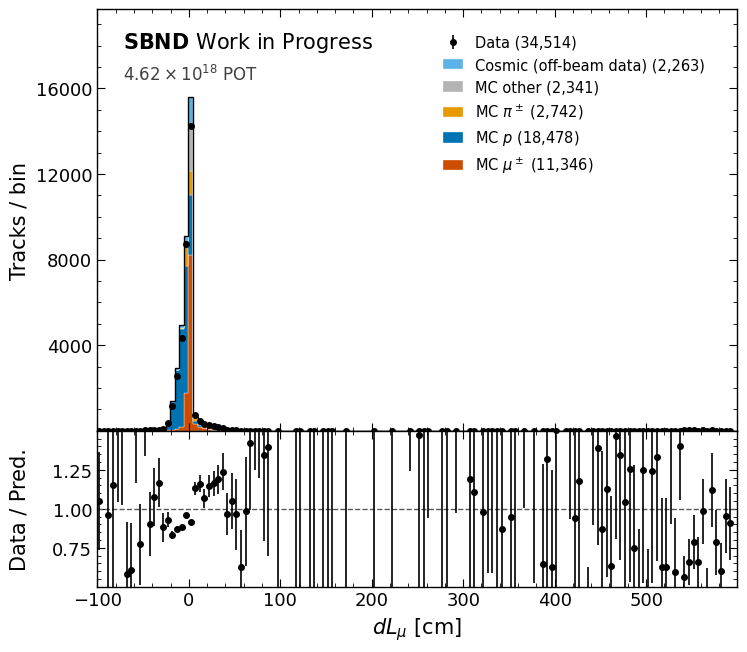

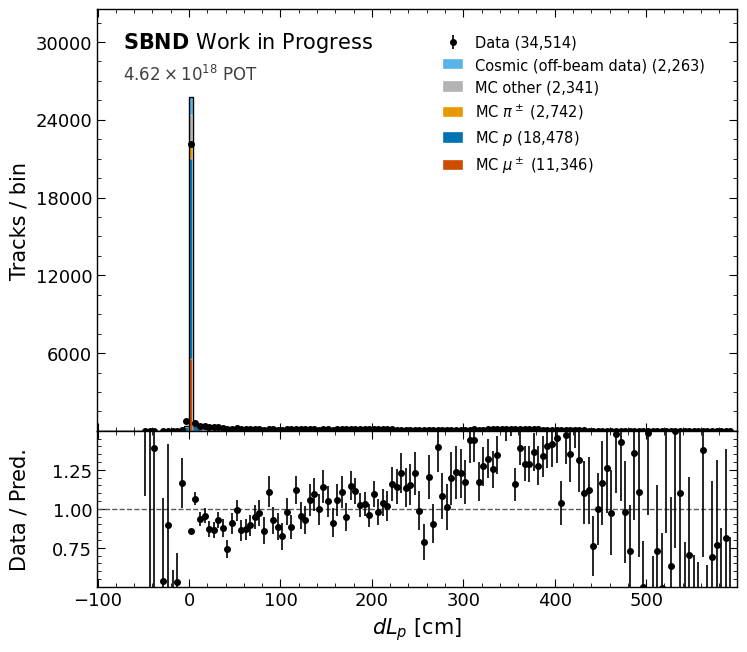

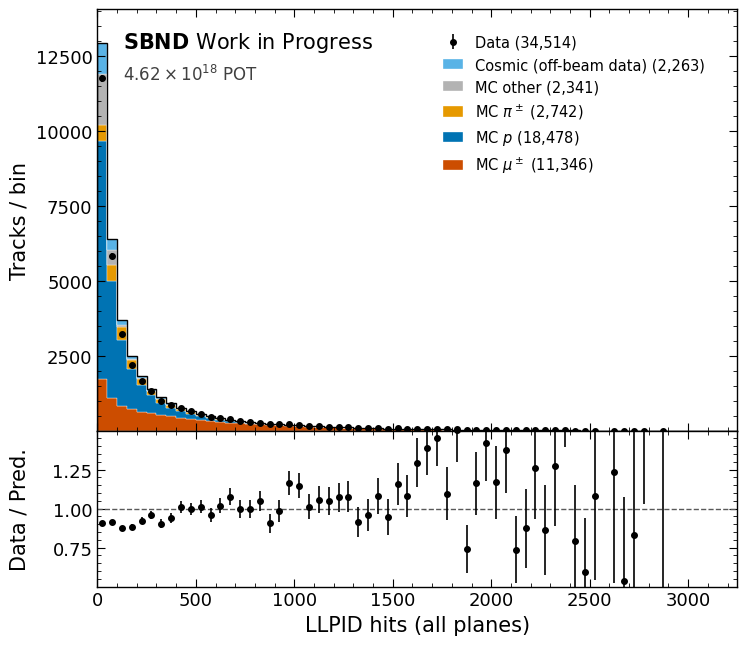

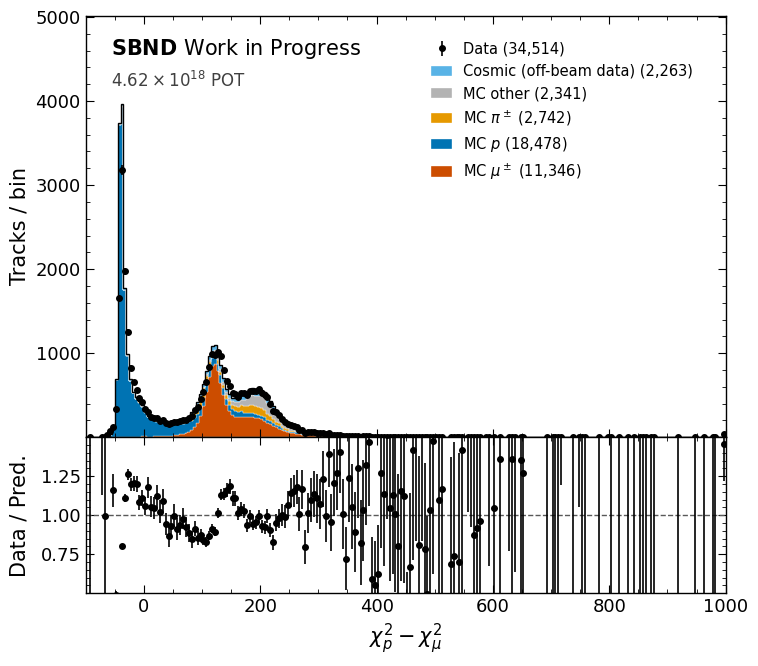

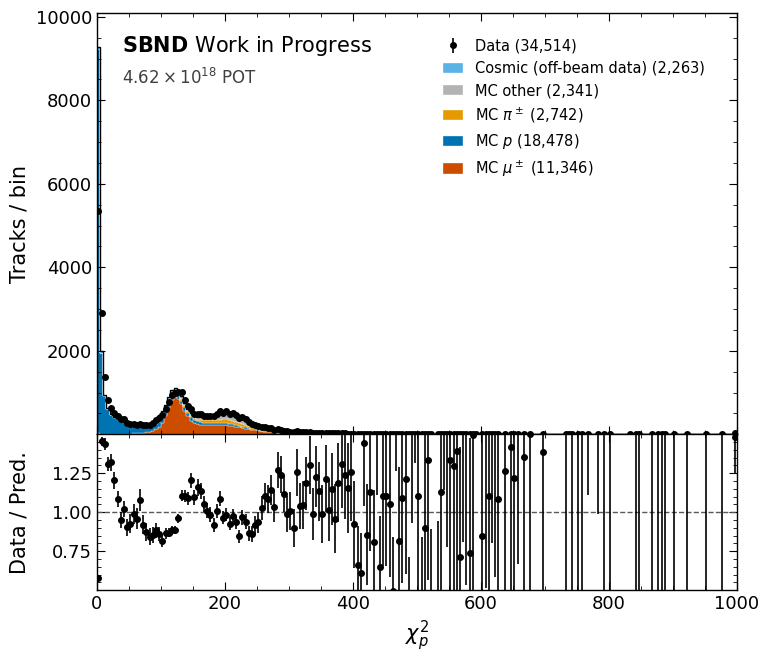

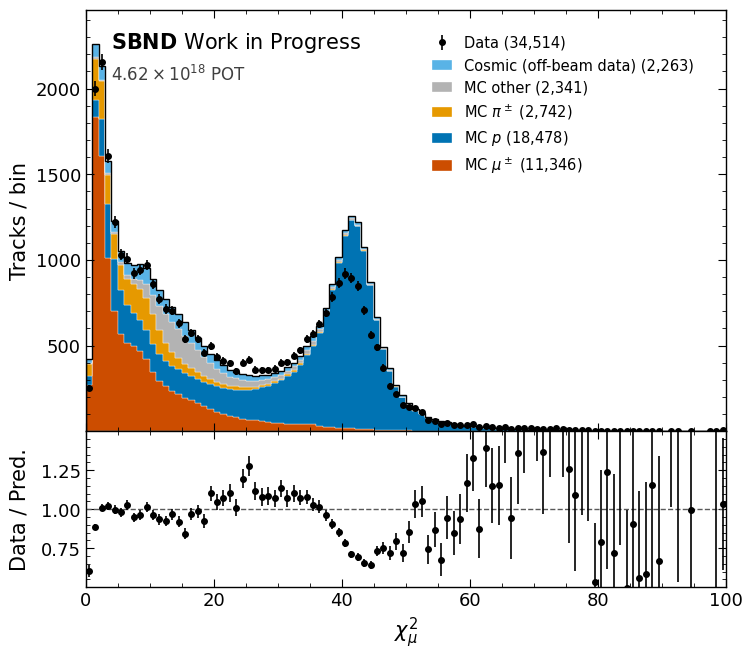

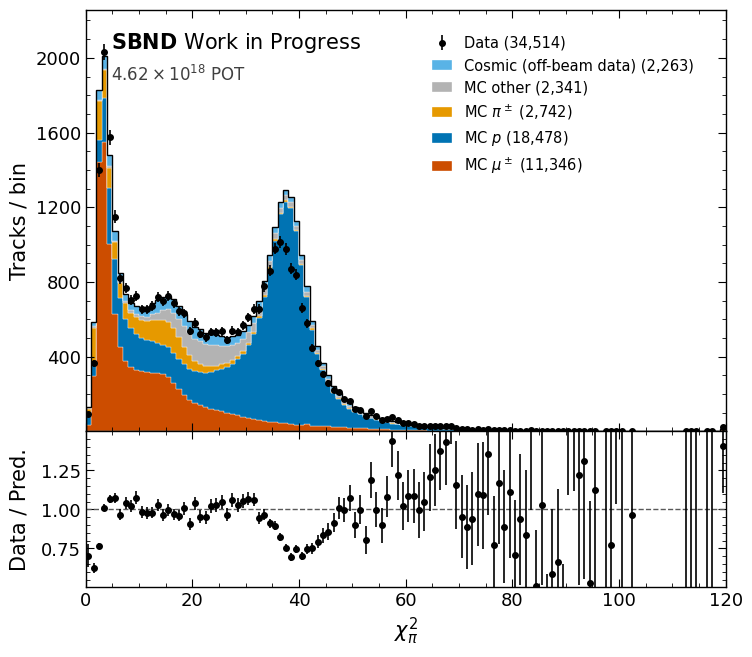

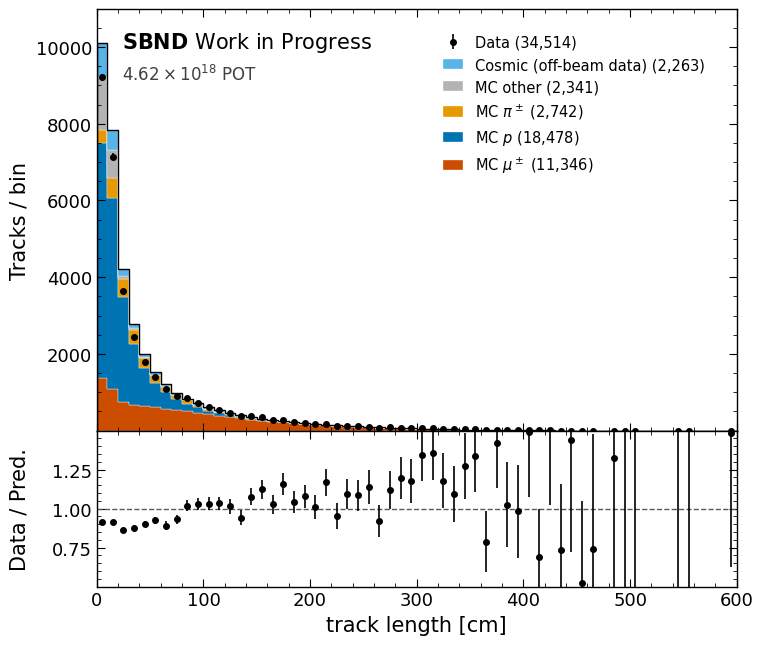

In [9]:
# Majority of this cell is cosmetic functions for plotting all the variables

OI = sbnd_style.OKABE_ITO_COLORS
STACK = {   # bottom to top
    "muon":   (r"MC $\mu^\pm$",          OI["vermilion"]),
    "proton": (r"MC $p$",                OI["blue"]),
    "pion":   (r"MC $\pi^\pm$",          OI["orange"]),
    "other":  ("MC other",               "0.70"),
    "cosmic": ("Cosmic (off-beam data)", OI["sky_blue"]),
}
plt.rcParams.update({
    "xtick.top": True, "ytick.right": True, "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.labelsize": 15, "legend.fontsize": 10.5, "hatch.linewidth": 0.6,
})

def pot_label(pot):
    e = int(np.floor(np.log10(pot)))
    return rf"${pot / 10**e:.2f}\times10^{{{e}}}$ POT"

def crop_range(total, lo_q=0.005, hi_q=0.995, pad=2):
    """first/last bin index (exclusive end) holding the central lo_q..hi_q of `total`, plus `pad` bins each side"""
    c = np.cumsum(total) / total.sum()
    i0 = max(np.searchsorted(c, lo_q) - pad, 0)
    i1 = min(np.searchsorted(c, hi_q) + 1 + pad, len(total))
    return i0, i1

def fit_headroom(fig, ax, bins, tops, artists, logy, bottom, gap=0.03):
    """raise the y-limit until nothing under any of `artists` (legend, labels) reaches it"""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    to_ax = ax.transAxes.inverted()
    x0, x1 = ax.get_xlim()
    top = tops.max() / 0.92                                    # default headroom
    for art in artists:
        bb = art.get_window_extent(r).transformed(to_ax)       # axes-fraction box
        lo, hi = x0 + bb.x0 * (x1 - x0), x0 + bb.x1 * (x1 - x0)
        under = (bins[1:] >= lo) & (bins[:-1] <= hi)
        if not under.any():
            continue
        peak, f = tops[under].max(), bb.y0 - gap
        if logy:
            top = max(top, bottom * (peak / bottom) ** (1 / f))
        else:
            top = max(top, peak / f)
    ax.set_ylim(bottom, top)

def plot_var(k, logy=False, save=None, crop=True, fold_max=1.5):
    _, bins, xlabel = VARS[k]
    assert len(bins) + 1 == len(H_data[k]["all"]), f"VARS[{k}] changed since filling, refill the histograms"

    # scaled content and sum of w^2 per component (MC and off-beam are unweighted counts x scale),
    # every array laid out as [underflow, bins..., overflow]
    comps = {c: (H_mc[k][c] * mc_scale, H_mc[k][c] * mc_scale**2) for c in CATS}
    comps["cosmic"] = (H_off[k]["all"] * offbeam_scale, H_off[k]["all"] * offbeam_scale**2)
    d = H_data[k]["all"]
    totals = {c: v.sum() for c, (v, _) in comps.items()}       # legend counts: every selected track
    n_data = d.sum()

    # bins to draw: the bulk if cropping, else all; everything left/right of them is "outside"
    inner = lambda a: a[1:-1]
    i0, i1 = crop_range(inner(d) + sum(inner(v) for v, _ in comps.values())) if crop else (0, len(bins) - 1)
    left  = lambda a: a[:i0 + 1].sum()
    right = lambda a: a[i1 + 1:].sum()
    kept  = lambda a: a[i0 + 1:i1 + 1].copy()
    bins  = bins[i0:i1 + 1]

    # outside tracks go into the edge bin if that bin then stays below fold_max x the tallest drawn bin;
    # otherwise they are left off the plot and quoted in the corner
    full = d + sum(v for v, _ in comps.values())
    peak = kept(full).max()
    fold_l = kept(full)[0]  + left(full)  <= fold_max * peak
    fold_r = kept(full)[-1] + right(full) <= fold_max * peak
    def show(a):
        out = kept(a)
        out[0]  += fold_l * left(a)
        out[-1] += fold_r * right(a)
        return out
    pred_all = sum(v for v, _ in comps.values())
    notes = [f"{s} {x:g}:  data {f(d):,.0f},  pred. {f(pred_all):,.0f}"
             for s, x, f, folded in [("<", bins[0], left, fold_l), (">", bins[-1], right, fold_r)]
             if not folded and f(full) > 0]
    comps = {c: (show(v), show(w2)) for c, (v, w2) in comps.items()}
    d = show(d)

    centers = (bins[1:] + bins[:-1]) / 2
    pred = sum(v for v, _ in comps.values())
    pred_err = np.sqrt(sum(w2 for _, w2 in comps.values()))

    fig = plt.figure(figsize=(8, 7.5))
    ax, rax = sbnd_style.split_canvas(fig, ysplit=0.27)

    bottom, handles = np.zeros_like(pred), []
    for c, (v, _) in comps.items():
        label, color = STACK[c]
        handles.append(ax.stairs(bottom + v, bins, baseline=bottom, fill=True, facecolor=color,
                                 edgecolor="white", lw=0.25, label=f"{label} ({totals[c]:,.0f})"))
        bottom = bottom + v
    ax.stairs(pred, bins, color="black", lw=1.0)
    m = d > 0
    data = ax.errorbar(centers[m], d[m], yerr=np.sqrt(d[m]), fmt="o", color="black", ms=4,
                       lw=1.2, capsize=0, label=f"Data ({n_data:,.0f})")

    # ratio panel
    with np.errstate(divide="ignore", invalid="ignore"):
        r, rerr = d / pred, np.sqrt(d) / pred
    rax.axhline(1, color="0.35", lw=1, ls="--")
    mr = m & (pred > 0)
    rax.errorbar(centers[mr], r[mr], yerr=rerr[mr], fmt="o", color="black", ms=4, lw=1.2, capsize=0)
    rax.set(ylim=(0.5, 1.5), ylabel="Data / Pred.", xlabel=xlabel, xlim=(bins[0], bins[-1]))
    rax.yaxis.set_major_locator(mticker.FixedLocator([0.75, 1.0, 1.25]))
    ax.tick_params(labelbottom=False)
    ax.set_ylabel("Tracks / bin")

    # legend on the emptier side, SBND label (and any not-drawn tracks) on the other
    tops = np.maximum(pred + pred_err, d + np.sqrt(d))
    half = len(tops) // 2
    leg_right = tops[half:].max() <= tops[:half].max()
    lx, tx = (0.97, 0.04) if leg_right else (0.03, 0.96)
    tha = "left" if leg_right else "right"
    t1 = ax.text(tx, 0.95, r"$\bf{SBND}$ Work in Progress", transform=ax.transAxes, va="top", ha=tha, fontsize=15)
    t2 = ax.text(tx, 0.87, pot_label(pot), transform=ax.transAxes, va="top", ha=tha, fontsize=12, color="0.25")
    labels = [t1, t2]
    if notes:
        labels.append(ax.text(tx, 0.80, "not drawn:\n" + "\n".join(notes), transform=ax.transAxes,
                              va="top", ha=tha, fontsize=10, color="0.25", linespacing=1.4))
    leg = ax.legend(handles=[data] + handles[::-1] , loc="upper right" if leg_right else "upper left",
                    bbox_to_anchor=(lx, 0.97), handlelength=1.4)

    if logy:
        ax.set_yscale("log")
        floor = 0.5
    else:
        floor = 0
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=6, prune="lower"))
    fit_headroom(fig, ax, bins, tops, [leg, *labels], logy, floor)

    fig.align_ylabels([ax, rax])
    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()


# Actually do the plotting for all the variables defined in VARS
for k in range(len(H_data)):
    plot_var(k, crop=False)


## PID Performance 

Running ROC Curves between particles

true muons / pions / protons: 1326127 320485 2159687
p vs mu, Likelihood                : cut    -0.816 -> p efficiency 0.940 at 2% mu mis-ID
p vs mu, Likelihood (no RR corr.)  : cut      5.81 -> p efficiency 0.898 at 2% mu mis-ID
p vs mu, $\chi^2$                  : cut      57.7 -> p efficiency 0.842 at 2% mu mis-ID
p vs pi, Likelihood                : cut     0.261 -> p efficiency 0.934 at 2% pi mis-ID
p vs pi, Likelihood (no RR corr.)  : cut      4.71 -> p efficiency 0.889 at 2% pi mis-ID
p vs pi, $\chi^2$                  : cut      36.5 -> p efficiency 0.809 at 2% pi mis-ID
pi vs mu, Likelihood                : cut      -109 -> pi efficiency 0.075 at 2% mu mis-ID
pi vs mu, Likelihood (no RR corr.)  : cut      -460 -> pi efficiency 0.106 at 2% mu mis-ID
pi vs mu, $\chi^2$                  : cut     -1.61 -> pi efficiency 0.032 at 2% mu mis-ID


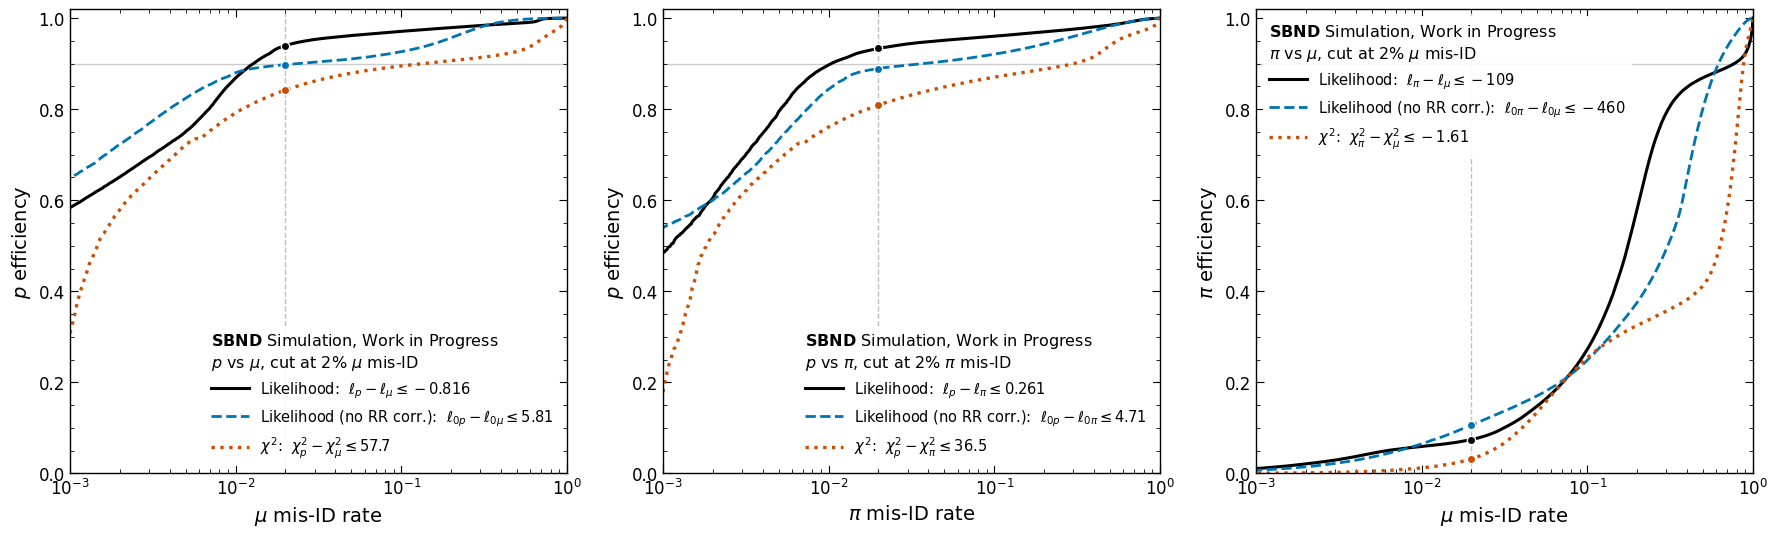

In [10]:
PERF_COLS = [("pfp", "trk", "llpid"), ("pfp", "trk", "chi2pid", "I2"), ("pfp", "trk", "truth", "p")]
perf = []
for f in sorted(glob.glob(SKIM + "llpid_skim_mc_*.h5")):
    d = pd.read_hdf(f, "evt")
    d = d[selection(d)]
    d = d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])]
    perf.append(d[[c for c in d.columns if any(c[:len(k)] == k for k in PERF_COLS)]])
    del d
    gc.collect()
perf = pd.concat(perf)
true = np.abs(perf["pfp", "trk", "truth", "p", "pdg"]).to_numpy()
print("true muons / pions / protons:", np.sum(true == 13), np.sum(true == 211), np.sum(true == 2212))

PDG = {"mu": 13, "pi": 211, "p": 2212}
NICE = {"mu": r"\mu", "pi": r"\pi", "p": "p"}
CHI_NAME = {"mu": "chi2_muon", "pi": "chi2_pion", "p": "chi2_proton"}
SCORES = {   # name: (score function, cut variable as a function of the two hypotheses)
    "Likelihood":               (lambda d, a, b: LL(d, "ell_" + a) - LL(d, "ell_" + b),
                                 lambda a, b: rf"\ell_{{{a}}} - \ell_{{{b}}}"),
    "Likelihood (no RR corr.)": (lambda d, a, b: LL(d, "ell0_" + a) - LL(d, "ell0_" + b),
                                 lambda a, b: rf"\ell_{{0{a}}} - \ell_{{0{b}}}"),
    r"$\chi^2$":                (lambda d, a, b: CHI(d, CHI_NAME[a]) - CHI(d, CHI_NAME[b]),
                                 lambda a, b: rf"\chi^2_{{{a}}} - \chi^2_{{{b}}}"),
}
STYLE = {   # colour + line style so the curves stay distinct without colour
    "Likelihood":               dict(color="black",         ls="-",  lw=2.2),
    "Likelihood (no RR corr.)": dict(color=OI["blue"],      ls="--", lw=2.0),
    r"$\chi^2$":                dict(color=OI["vermilion"], ls=":",  lw=2.4),
}
WP = 0.02   # mis-ID working point quoted in the legend

def roc(sig, bkg):
    """exact ROC selecting score <= cut: (background mis-ID, signal efficiency) at every threshold"""
    sig, bkg = sig[np.isfinite(sig)], bkg[np.isfinite(bkg)]
    y = np.r_[np.ones(len(sig)), np.zeros(len(bkg))][np.argsort(np.r_[sig, bkg], kind="stable")]
    return np.r_[0, np.cumsum(1 - y) / len(bkg)], np.r_[0, np.cumsum(y) / len(sig)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
grid = np.geomspace(1e-4, 1, 800)   # plotting grid; the full curve is used for the working point
for ax, (a, b) in zip(axes, [("p", "mu"), ("p", "pi"), ("pi", "mu")]):
    high = False
    for name, (score, sym) in SCORES.items():
        s = np.asarray(score(perf, a, b), float)
        sig, bkg = s[true == PDG[a]], s[true == PDG[b]]
        fpr, tpr = roc(sig, bkg)
        cut = np.quantile(bkg[np.isfinite(bkg)], WP)   # selecting score <= cut keeps WP of the background
        eff = np.interp(WP, fpr, tpr)
        high |= eff > 0.5
        ax.plot(grid, np.interp(grid, fpr, tpr), **STYLE[name], label=rf"{name}:  ${sym(NICE[a], NICE[b])} \leq {cut:.3g}$")
        ax.plot(WP, eff, "o", color=STYLE[name]["color"], ms=6, mec="white", mew=1, zorder=5)
        print(f"{a} vs {b}, {name:26s}: cut {cut:9.3g} -> {a} efficiency {eff:.3f} at {100 * WP:.0f}% {b} mis-ID")
    ax.axvline(WP, color="0.75", lw=1, ls="--", zorder=0)
    ax.set(xscale="log", xlim=(1e-3, 1), ylim=(0, 1.02),
           xlabel=rf"${NICE[b]}$ mis-ID rate", ylabel=rf"${NICE[a]}$ efficiency")
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
    ax.axhline(0.9, color="0.8", lw=1, zorder=0)

    ax.tick_params(which="both", top=True, right=True, direction="in", labelsize=12)
    ax.xaxis.label.set_size(14); ax.yaxis.label.set_size(14)
    # curves high -> lower right is empty; curves low -> upper left is empty
    ax.legend(loc="lower right" if high else "upper left", fontsize=10.5, handlelength=2.6,
              title=(r"$\bf{SBND}$ Simulation, Work in Progress" + "\n"
                     + rf"${NICE[a]}$ vs ${NICE[b]}$, cut at {100 * WP:.0f}% ${NICE[b]}$ mis-ID"),
              title_fontsize=11.5, alignment="left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
fig.tight_layout()
plt.show()


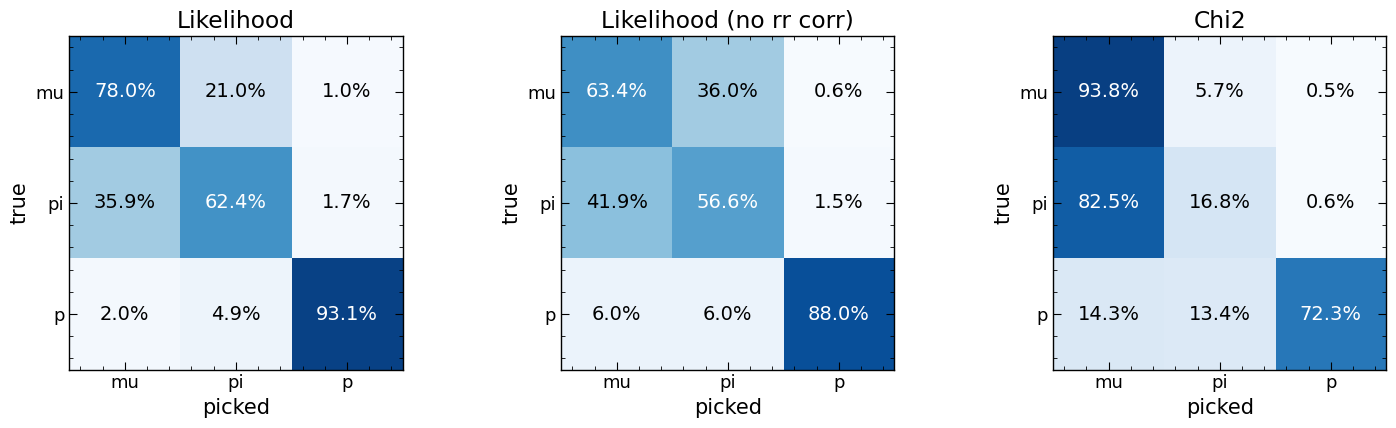

In [12]:
# Confusion matrices of the best hypothesis using the naive cuts (lowest score wins)
HYPS = ["mu", "pi", "p"]
best = {
    "Likelihood":              np.argmin(np.column_stack([LL(perf, "ell_" + h) for h in HYPS]), axis=1),
    "Likelihood (no rr corr)": np.argmin(np.column_stack([LL(perf, "ell0_" + h) for h in HYPS]), axis=1),
    "Chi2":                    np.argmin(np.column_stack([CHI(perf, CHI_NAME[h]) for h in HYPS]), axis=1),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (name, pick) in enumerate(best.items()):
    mat = np.array([[np.mean(pick[true == PDG[t]] == j) for j in range(3)] for t in HYPS])
    ax[k].imshow(mat, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax[k].text(j, i, f"{100 * mat[i, j]:.1f}%", ha="center", va="center", color="white" if mat[i, j] > 0.5 else "black")
    ax[k].set(title=name, xticks=range(3), yticks=range(3), xticklabels=HYPS, yticklabels=HYPS, xlabel="picked", ylabel="true")
plt.tight_layout()
plt.show()


Maybe the likelihood is outperforming chi2 simply because it fails way more (produces failure code NaN, chi2 gives 0) and only keeps good runs. Construct a fail matrix where the $\ell$ and $\chi^2$ are related to eachother on a track by track basis.

selected truth-matched mu/pi/p tracks (chi2 not required): 2331600


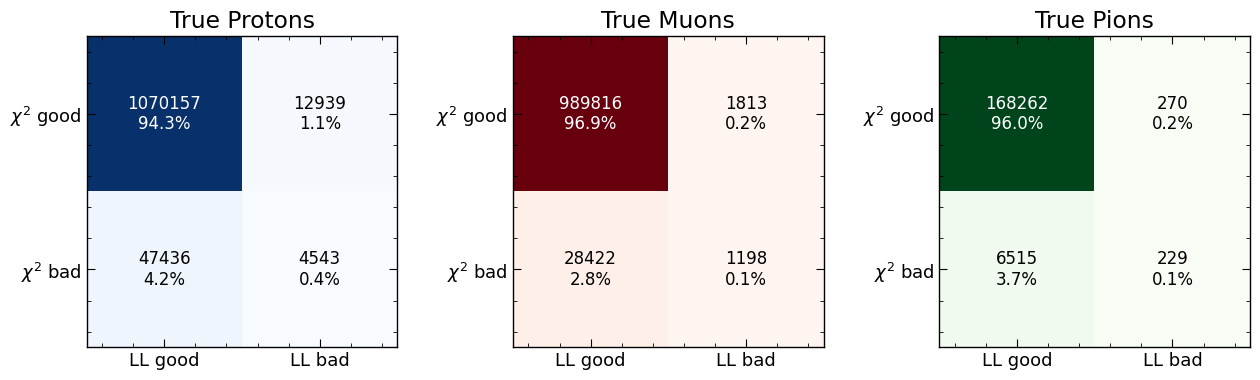

In [14]:
def fail_sample(skim=SKIM):
    """selected, truth-matched mu/pi/p MC tracks, chi2 NOT required: same cuts as the SLICE selection cell"""
    SLICE = ["file", "__ntuple", "entry", "rec.slc..index"]

    def in_volume(x, y, z):
        x_region  = (np.abs(x) > 5) & (np.abs(x) < 190)
        z_region1 = (z > 10) & (z < 250) & (y > -190) & (y < 190)
        z_region2 = (z > 250) & (z < 450) & (y > -190) & (y < 100) & (x < 0)
        z_region3 = (z > 250) & (z < 450) & (y > -190) & (y < 190) & (x > 0)
        return x_region & (z_region1 | z_region2 | z_region3)

    def trk_contained(df):
        s = [df["pfp", "trk", "start", c] for c in "xyz"]
        e = [df["pfp", "trk", "end", c] for c in "xyz"]
        tpc = np.sign(df["slc", "vertex", "x"])
        return in_volume(*s) & in_volume(*e) & (np.sign(s[0]) == tpc) & (np.sign(e[0]) == tpc)

    def select(df):
        no_trk = df["pfp", "trk", "len"].isna()
        all_contained = (trk_contained(df) | no_trk).groupby(level=SLICE).transform("all")
        return (in_volume(df["slc", "vertex", "x"], df["slc", "vertex", "y"], df["slc", "vertex", "z"])
                & (df["slc", "is_clear_cosmic"] == 0)
                & (df["slc", "barycenterFM", "flashPEs"] > 3000)
                & all_contained
                & (df["pfp", "trk", "len"] > 3)
                & (df["pfp", "trackScore"] > 0.5)
                & (df["pfp", "dist_to_vertex"] < 6))

    keep = [("pfp", "trk", "truth", "p"), ("pfp", "trk", "llpid"), ("pfp", "trk", "chi2pid", "I2")]
    out = []
    for f in sorted(glob.glob(skim + "llpid_skim_mc_*.h5")):
        d = pd.read_hdf(f, "evt")
        d = d[select(d)]
        d = d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])]
        out.append(d[[c for c in d.columns if any(c[:len(k)] == k for k in keep)]])
        del d
        gc.collect()
    out = pd.concat(out)
    print(f"selected truth-matched mu/pi/p tracks (chi2 not required): {len(out)}")
    return out


def fail_matrices(df):
    """rows = chi2 (good, bad), columns = llpid (good, bad)"""
    pdg = np.abs(df["pfp", "trk", "truth", "p", "pdg"])
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for a, (name, code, cmap) in zip(ax, [("True Protons", 2212, "Blues"), ("True Muons", 13, "Reds"), ("True Pions", 211, "Greens")]):
        d = df[pdg == code]
        ll_bad  = d["pfp", "trk", "llpid", "ell_mu"].isna().to_numpy()
        chi2 = d["pfp", "trk", "chi2pid", "I2"][["chi2_proton", "chi2_muon", "chi2_pion"]]
        chi_bad = (chi2 == 0).any(axis=1).to_numpy()
        mat = np.array([[np.sum(~chi_bad & ~ll_bad), np.sum(~chi_bad & ll_bad)],
                        [np.sum(chi_bad & ~ll_bad),  np.sum(chi_bad & ll_bad)]])
        a.imshow(mat, cmap=cmap)
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{mat[i, j]}\n{100 * mat[i, j] / mat.sum():.1f}%", ha="center", va="center", fontsize=12,
                       color="white" if mat[i, j] > mat.max() / 2 else "black")
        a.set(title=name, xticks=[0, 1], yticks=[0, 1], xticklabels=["LL good", "LL bad"],
              yticklabels=[r"$\chi^2$ good", r"$\chi^2$ bad"])
    plt.tight_layout()
    plt.show()


fail_df = fail_sample()
fail_matrices(fail_df)


We actually see the opposite, there are more $\chi^2$ failure modes than likelihood! Likely because we are using all three planes, while $\chi^2$ only utilizes a single plane.

## Correction on range-based Energy

In [25]:
import gc
from matplotlib.colors import LogNorm

TRUTH_COLS = [("pfp", "trk", "llpid"),  ("pfp", "trk", "truth", "p"), ("pfp", "trk", "len")]

truth = []
for f in sorted(glob.glob(SKIM + "llpid_skim_mc_*.h5")):
    d = pd.read_hdf(f, "evt")
    d = d[selection(d)]
    d = d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])]
    truth.append(d[[c for c in d.columns if any(c[:len(k)] == k for k in TRUTH_COLS)]])
    del d
    gc.collect()
truth = pd.concat(truth)
print(f"truth-matched mu/pi/p tracks: {len(truth)}")


truth-matched mu/pi/p tracks: 3806299


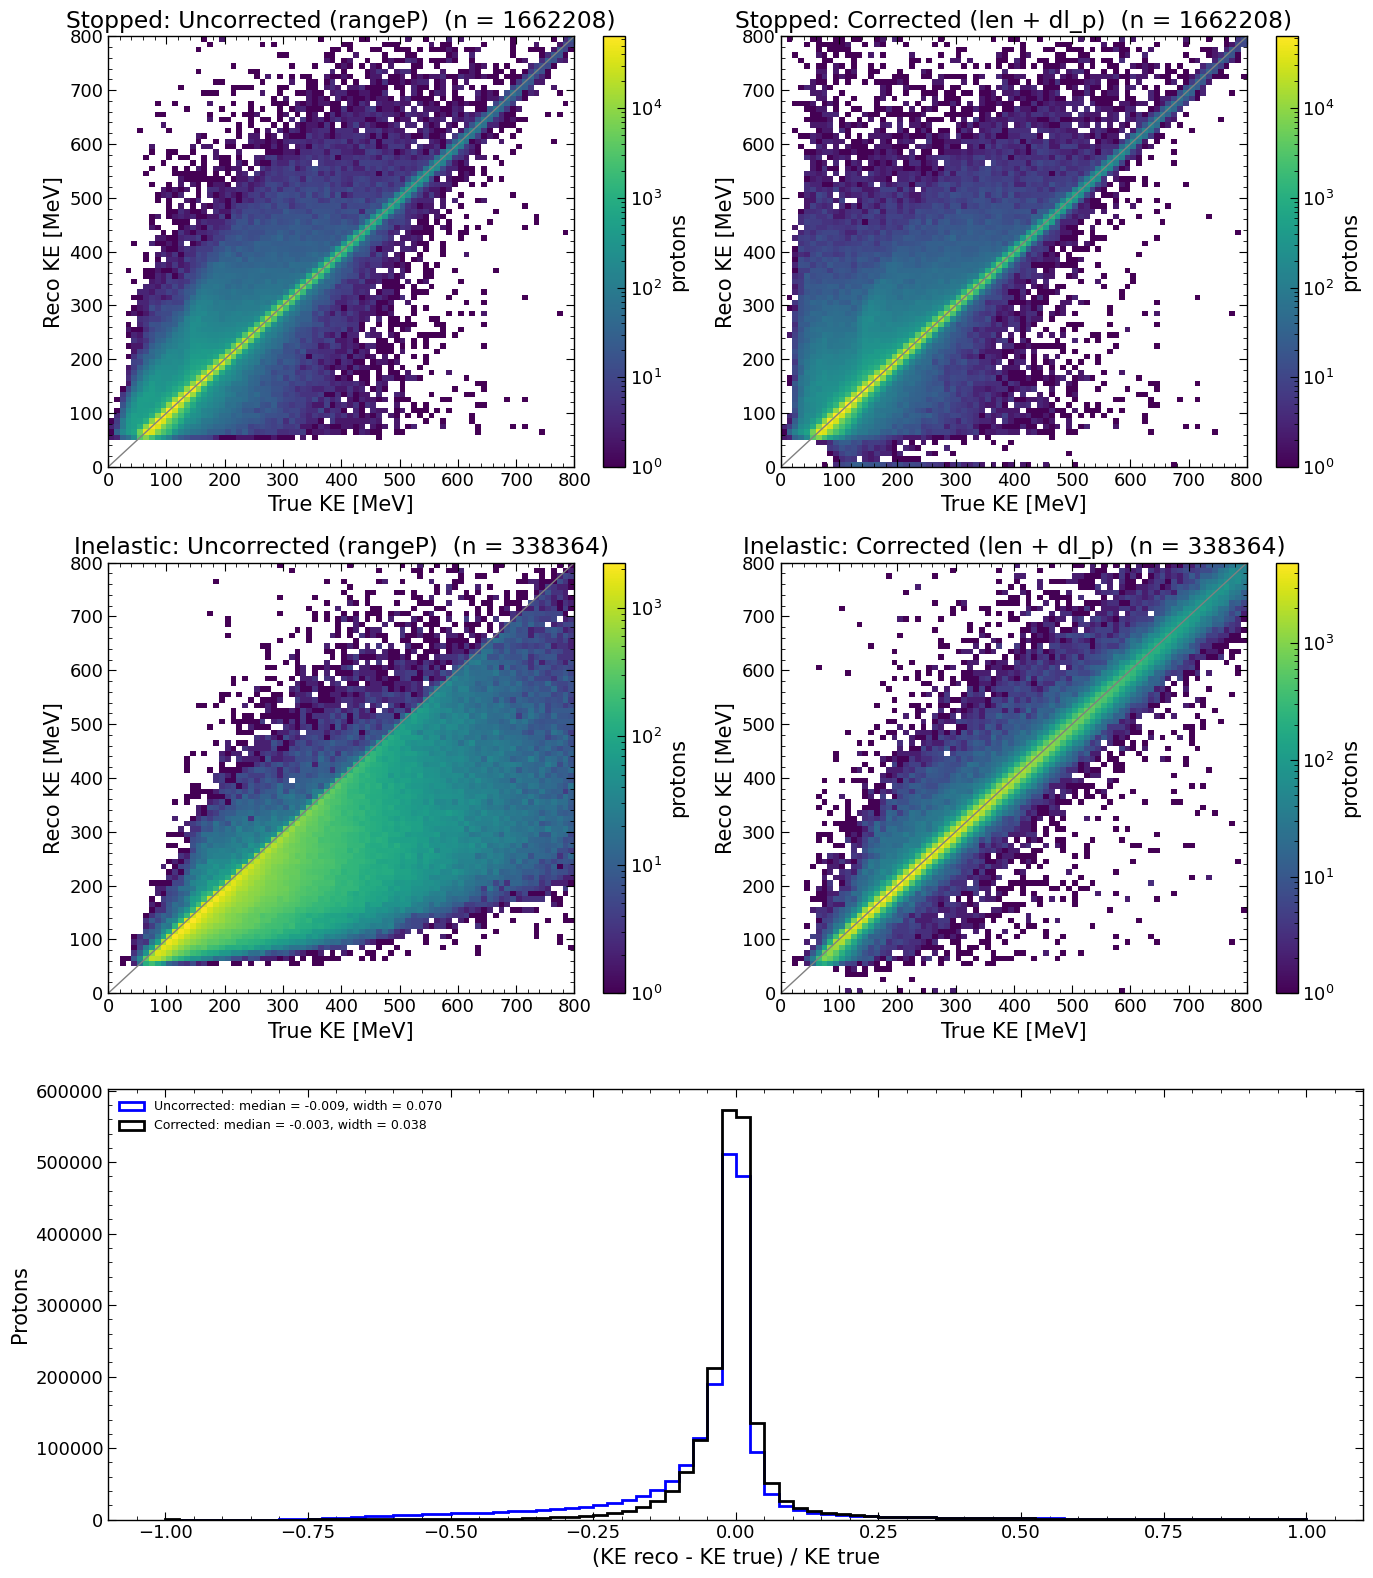

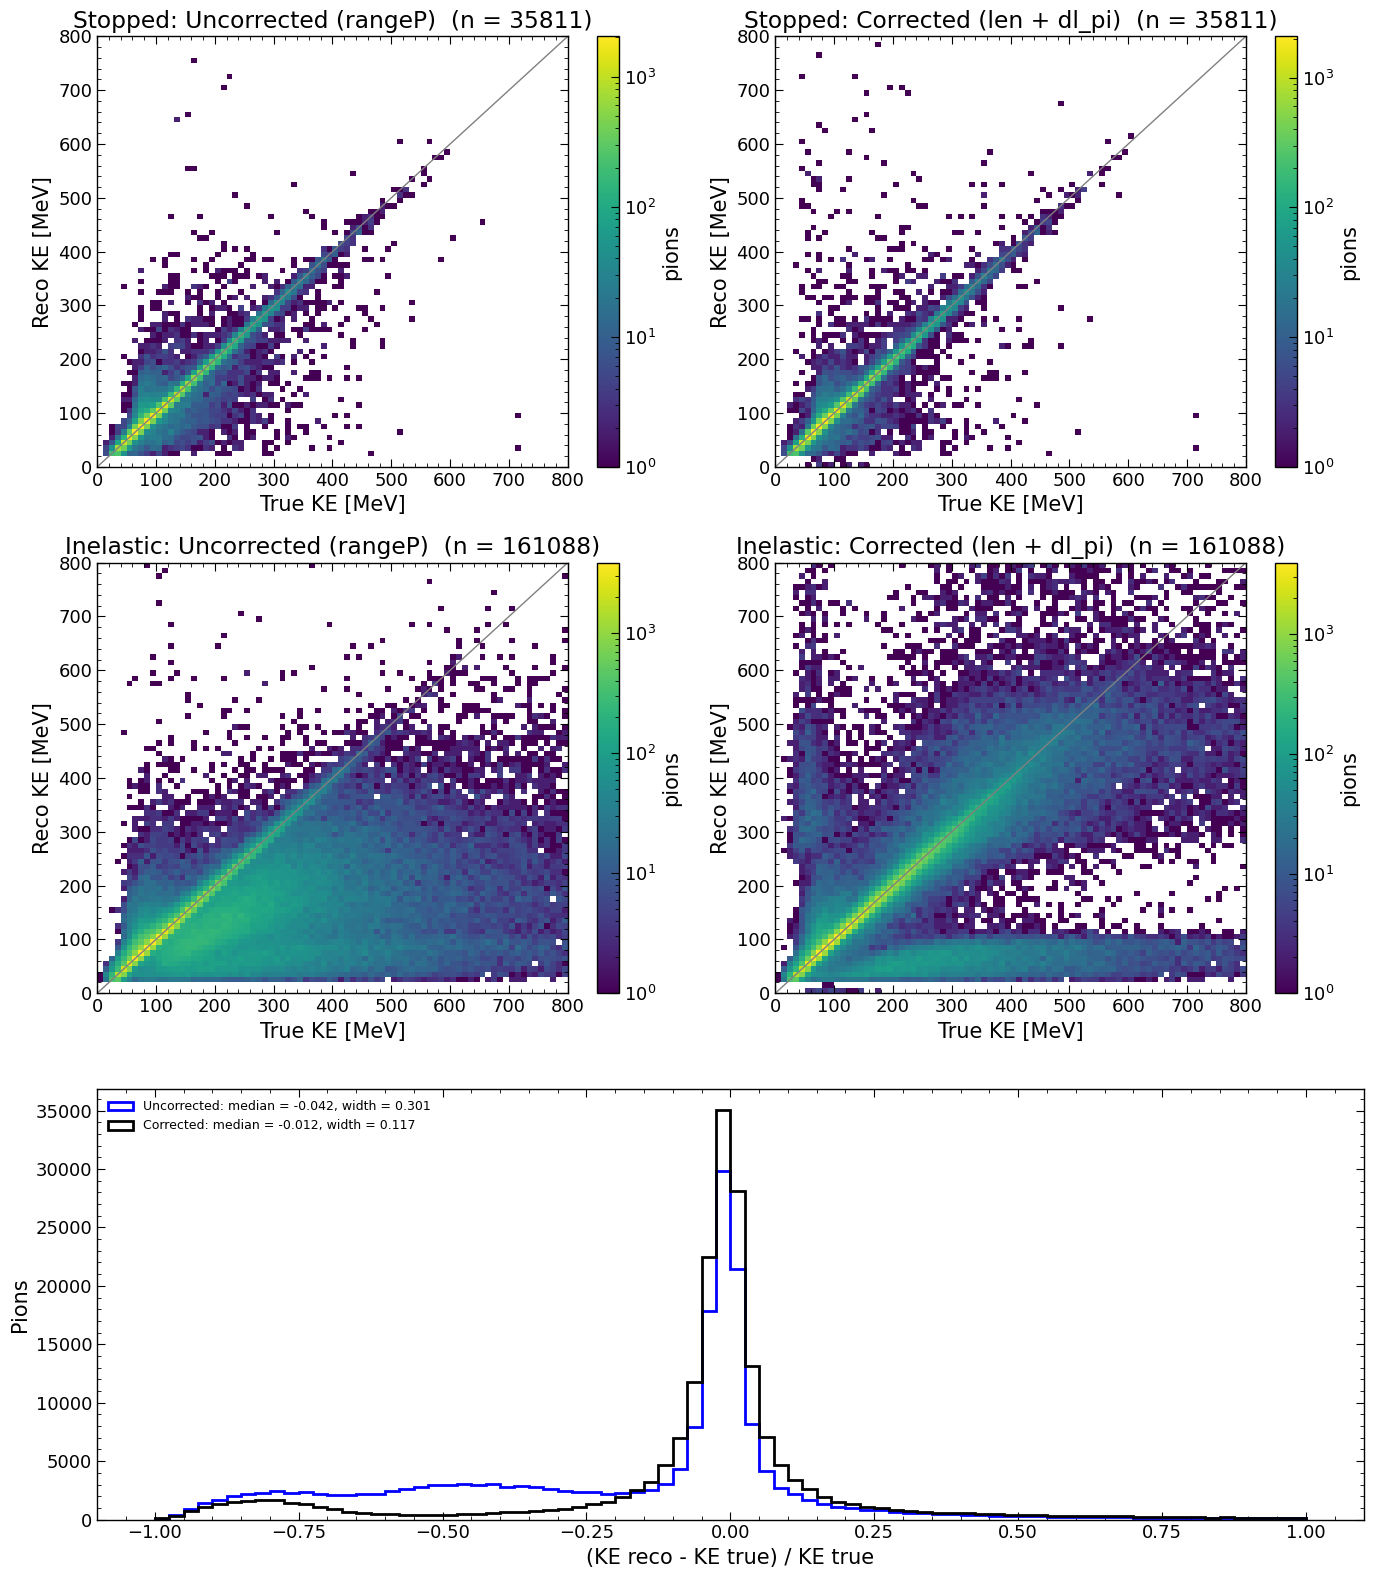

In [26]:
PDGS    = {"p": 2212, "pi": 211}
MASS    = {"p": 0.938272, "pi": 0.13957039}   # GeV
RANGEP  = {"p": "p_proton", "pi": "p_pion"}
STOPPED = {"p": [54], "pi": [ 45]}           # hIoni , CaptureAtRest
INEL    = {"p": [7],  "pi": [3, 9, 10]}           # protonInelastic / pi+-Inelastic / Decay
NAME    = {"p": "Protons", "pi": "Pions"}

def ke_panels(df, h, ke_max=800, nbins=80, pid=False):
    d = df[(np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == PDGS[h])
           & (df["pfp", "trk", "truth", "p", "cont_tpc"] == 1)
           & df["pfp", "trk", "llpid", "ell_" + h].notna()]
    if pid:   # only tracks the likelihood identifies as hypothesis h
        ell = d["pfp", "trk", "llpid"][["ell_mu", "ell_pi", "ell_p"]]
        d = d[ell.idxmin(axis=1) == ("ell_" + h, "", "")]
    m = MASS[h]
    ke_true = ((d["pfp", "trk", "truth", "p", "startE"] - m) * 1000).to_numpy()
    table = llpid._ke_table(h)
    ke_unc = np.interp(d["pfp", "trk", "len"], table["range"], table["ke"])
    ke_cor = np.interp(d["pfp", "trk", "len"] + d["pfp", "trk", "llpid", "dl_" + h], table["range"], table["ke"])
    ep = d["pfp", "trk", "truth", "p", "end_process"]
    groups = {"Stopped": ep.isin(STOPPED[h]).to_numpy(), "Inelastic": ep.isin(INEL[h]).to_numpy()}
    recos = {"Uncorrected (rangeP)": ke_unc, f"Corrected (len + dl_{h})": ke_cor}

    fig = plt.figure(figsize=(14, 16))
    gs = fig.add_gridspec(3, 2)
    edges = np.linspace(0, ke_max, nbins + 1)
    for i, (gname, g) in enumerate(groups.items()):
        for j, (rname, ke) in enumerate(recos.items()):
            a = fig.add_subplot(gs[i, j])
            *_, im = a.hist2d(ke_true[g], ke[g], bins=edges, norm=LogNorm(), cmap="viridis")
            # *_, im = a.hist2d(ke_true[g], ke[g], bins=edges, cmap="viridis")
            fig.colorbar(im, ax=a, label=NAME[h].lower())
            a.plot([0, ke_max], [0, ke_max], color="gray", lw=1)
            a.set(title=f"{gname}: {rname}  (n = {g.sum()})", xlabel="True KE [MeV]", ylabel="Reco KE [MeV]")

    rax = fig.add_subplot(gs[2, :])
    for (rname, ke), color in zip(recos.items(), ["blue", "black"]):
        res = (ke - ke_true) / ke_true
        res = res[np.isfinite(res)]
        width = (np.percentile(res, 84) - np.percentile(res, 16)) / 2
        rax.hist(res, bins=np.linspace(-1, 1, 81), histtype="step", lw=2, color=color, label=f"{rname.split(' ')[0]}: median = {np.median(res):+.3f}, width = {width:.3f}", density=False)
    rax.set(xlabel="(KE reco - KE true) / KE true", ylabel=NAME[h])
    rax.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()



#Require PID to be correct for the track: 
ke_panels(truth, "p", pid=True)
ke_panels(truth, "pi", pid=True)

#Include all true tracks of this PID:
# ke_panels(truth, "p")
# ke_panels(truth, "pi")
